# Определение возраста покупателей

# Введениe

**Описание проекта:**

Сетевой супермаркет внедряет систему компьютерного зрения для обработки фотографий покупателей. Фотофиксация в прикассовой зоне поможет определять возраст клиентов, чтобы:
- Анализировать покупки и предлагать товары, которые могут заинтересовать покупателей этой возрастной группы;
- Контролировать добросовестность кассиров при продаже алкоголя.


**Цель проекта**:

Построить модель, которая по фотографии определяет приблизительный возраст клиента

**Исходные данные**:

Данные взяты с сайта [ChaLearn Looking at People](https://chalearnlap.cvc.uab.es/dataset/26/description/)

Изображения разделены на 4113 обучающих, 1500 валидационных и 1978 тестовых изображений, которые находятся в папках train/, valid/ и test/.


# Библиотеки

In [17]:
import os
import random

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from PIL import Image

try:
    from tensorflow.keras.applications.resnet50 import ResNet50
    from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.optimizers import Adam
    from tensorflow.keras.preprocessing.image import ImageDataGenerator
    from tensorflow.keras.callbacks import ReduceLROnPlateau
except ImportError:
    !pip install tensorflow
    from tensorflow.keras.applications.resnet50 import ResNet50
    from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.optimizers import Adam
    from tensorflow.keras.preprocessing.image import ImageDataGenerator
    from tensorflow.keras.callbacks import ReduceLROnPlateau

# Первичный обзор данных

Загрузим данные:

In [18]:
base_path = "/kaggle/input/datasets/zdoronkov/please-upload-at-least-one-file/final_data/"

df_train = pd.read_csv(base_path + "gt_train.csv")
df_valid = pd.read_csv(base_path + "gt_valid.csv")
df_test = pd.read_csv(base_path + "gt_test.csv")

Отобразим первичную информацию о данных:

In [19]:
# Словарь с названиями df
dfs = {
    'df_train': df_train, 
    'df_valid': df_valid,
    'df_test': df_test
}

In [20]:
for name, df in dfs.items():
    print(f"=== Датафрейм: {name} ===")
    display(df.info())

=== Датафрейм: df_train ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 133935 entries, 0 to 133934
Data columns (total 5 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   file_name      133935 non-null  object
 1   real_age       133935 non-null  int64 
 2   apparent_age   133935 non-null  int64 
 3   worker_age     133935 non-null  int64 
 4   worker_gender  25374 non-null   object
dtypes: int64(3), object(2)
memory usage: 5.1+ MB


None

=== Датафрейм: df_valid ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51257 entries, 0 to 51256
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   file_name      51257 non-null  object
 1   real_age       51257 non-null  int64 
 2   apparent_age   51257 non-null  int64 
 3   worker_age     51257 non-null  int64 
 4   worker_gender  9708 non-null   object
dtypes: int64(3), object(2)
memory usage: 2.0+ MB


None

=== Датафрейм: df_test ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 75464 entries, 0 to 75463
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   file_name      75464 non-null  object
 1   real_age       75464 non-null  int64 
 2   apparent_age   75464 non-null  int64 
 3   worker_age     75464 non-null  int64 
 4   worker_gender  75397 non-null  object
dtypes: int64(3), object(2)
memory usage: 2.9+ MB


None

In [21]:
for name, df in dfs.items():
    print(f"=== Датафрейм: {name} ===")
    display(df.head())

=== Датафрейм: df_train ===


,file_name,real_age,apparent_age,worker_age,worker_gender
0,000000.jpg,4,5,36,male
1,000000.jpg,4,4,38,female
2,000000.jpg,4,7,52,female
3,000000.jpg,4,5,50,male
4,000000.jpg,4,4,52,female


=== Датафрейм: df_valid ===


,file_name,real_age,apparent_age,worker_age,worker_gender
0,004113.jpg,29,19,48,NaN
1,004113.jpg,29,22,-1,NaN
2,004113.jpg,29,32,61,NaN
3,004113.jpg,29,19,48,NaN
4,004113.jpg,29,30,50,NaN


=== Датафрейм: df_test ===


,file_name,real_age,apparent_age,worker_age,worker_gender
0,005613.jpg,19,25,53,female
1,005613.jpg,19,20,50,male
2,005613.jpg,19,29,35,male
3,005613.jpg,19,25,29,male
4,005613.jpg,19,19,58,male


Данные содержат колонки, которые не понадобятся для обучения модели: `apparent_age, worker_age, worker_gender`. Удалим их, оставим только реальный возраст

In [22]:
for name, df in dfs.items():
    df.drop(columns=['apparent_age', 'worker_age', 'worker_gender'], inplace=True)
    print(df.columns)

Index(['file_name', 'real_age'], dtype='object')
Index(['file_name', 'real_age'], dtype='object')
Index(['file_name', 'real_age'], dtype='object')


Проверим данные на наличие дубликатов:

In [23]:
for name, df in dfs.items():
    num_duplicates = df.duplicated().sum()
    print(f'Количество дубликатов в {name}:', num_duplicates)
    

Количество дубликатов в df_train: 129822
Количество дубликатов в df_valid: 49757
Количество дубликатов в df_test: 73486


Наличие дубликатов обусловлено тем, что одну и ту же фотографию оценивали разные люди. После удаления признаков `apparent_age, worker_age, worker_gender`, строки стали дублировать друг друга. 

Удалим дубликаты:

In [24]:
for name, df in dfs.items():
    df.drop_duplicates(inplace=True)
    num_duplicates = df.duplicated().sum()
    print(f'Количество дубликатов в {name}:', num_duplicates)

Количество дубликатов в df_train: 0
Количество дубликатов в df_valid: 0
Количество дубликатов в df_test: 0


# Исследовательский анализ данных

## Распределение данных

Отразим распределения возраста людей в тренировочной выборке:

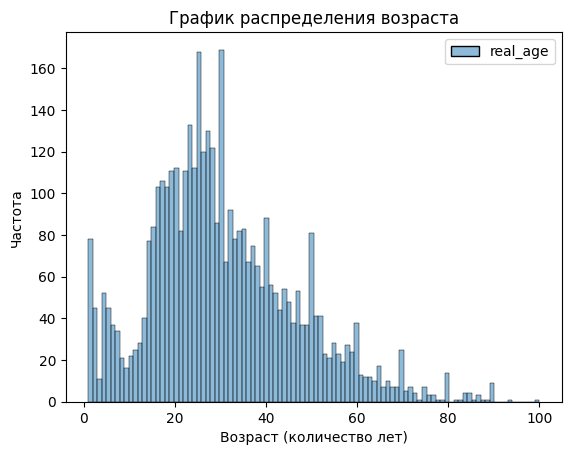

In [25]:
sns.histplot(
    data=df_train,
    bins=100
)
plt.xlabel('Возраст (количество лет)')
plt.ylabel('Частота')
plt.title('График распределения возраста');

Наблюдения:
- **Основная аудитория:** Большая часть значений сосредоточена в диапазоне от 20 до 40 лет.   
- **Дети:** Заметен явный всплеск в самом начале графика — около 1 года.
- **Круглые даты:** Присутствуют характерные локальные пики на «круглых» цифрах — 40, 50, 60, 70 лет, что может говорить о склонности людей или асессоров округлять возраст.   
- **Форма распределения:** Распределение скошено вправо; после 50-60 лет количество фотографий плавно убывает, доходя до единичных случаев в районе 90–100 лет.

## Фотографии

Файлы с фотографиями имеют названия отличные от названий file_name в датафреймах. Исправим это: 

In [26]:
for df in [df_train, df_valid, df_test]:
    df['file_name'] = df['file_name'].str.replace('.jpg', '.jpg_face.jpg', regex=False)

df_train.head()

,file_name,real_age
0,000000.jpg_face.jpg,4
36,000001.jpg_face.jpg,18
99,000002.jpg_face.jpg,80
137,000003.jpg_face.jpg,50
175,000004.jpg_face.jpg,17


Выведем 12 случайных фотографий с указанием возраста людей:

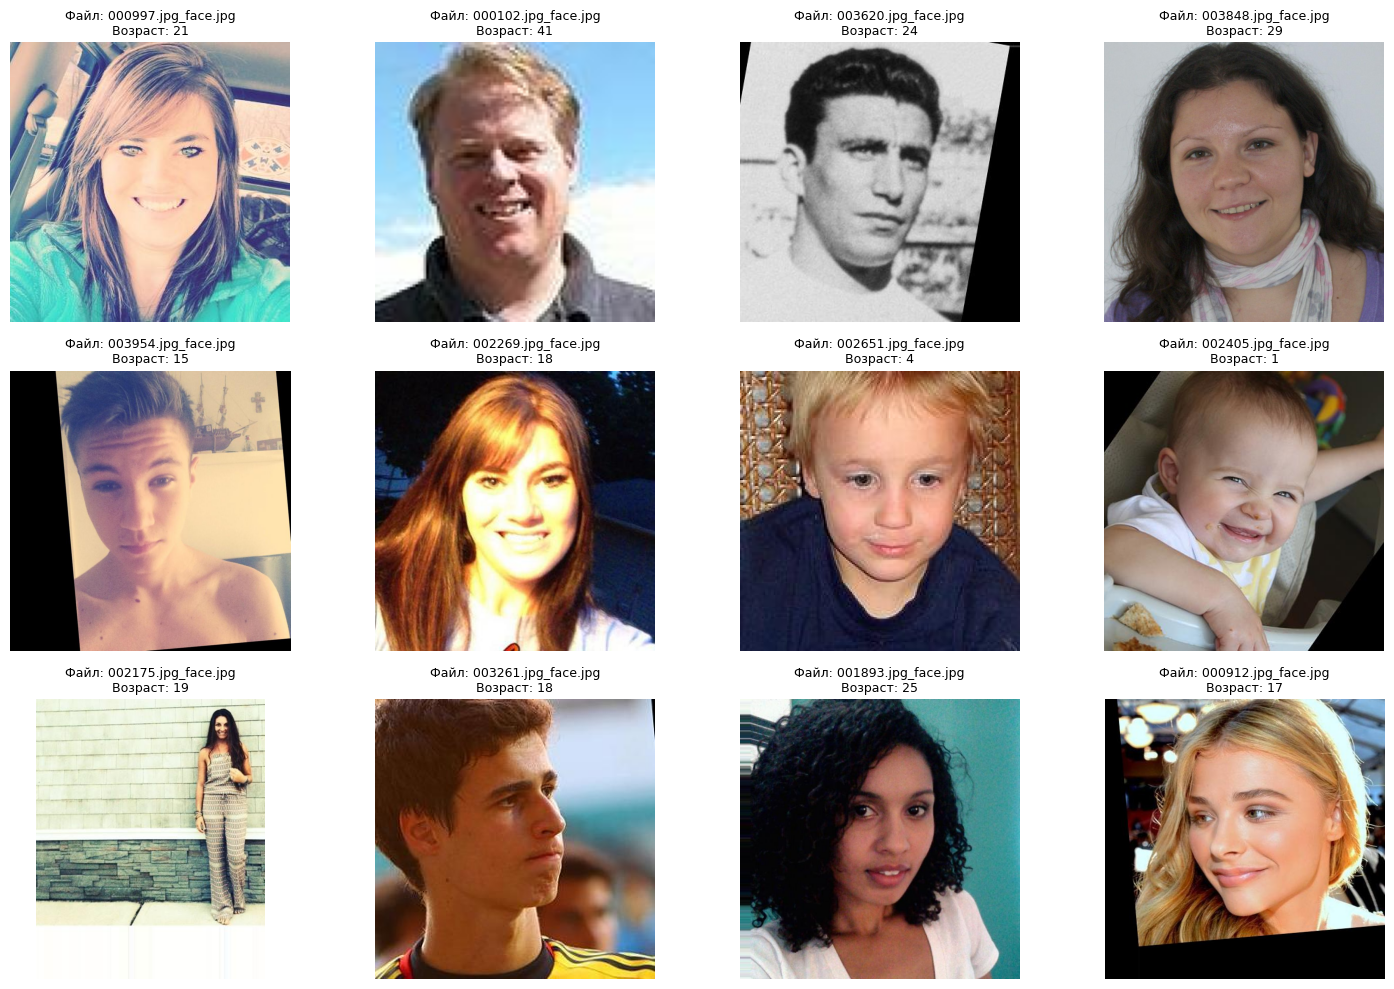

In [27]:
path_to_images = "/kaggle/input/datasets/zdoronkov/please-upload-at-least-one-file/final_data/train"

fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(15, 10))

axes_flat = axes.flatten()

for i, ax in enumerate(axes_flat):
    
    random_row = df_train.sample(n=12).iloc[0]
    img_name = random_row["file_name"]
    age = random_row["real_age"] 

    img_path = os.path.join(path_to_images, img_name)
    img = Image.open(img_path)

    ax.imshow(img)
    
    ax.set_title(f"Файл: {img_name}\nВозраст: {age}", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

Возраст людей соответсвует представленным фотографиям

# Моделирование

Для решения задачи регрессии — определения возраста человека по фотографии — построим и обучим сверточную нейронную сеть на базе предобученной архитектуры **ResNet50**.

**Архитектура нейронной сети:**

* **Бэкбон (Backbone):** `ResNet50` без верхней классификационной части (`include_top=False`, `input_shape=(224, 224, 3)`), что позволяет извлекать из изображений ключевые визуальные признаки (формы, текстуры, черты лица).
* **Обучаемость бэкбона:** Веса базовой модели разморожены (`backbone.trainable = True`) для тонкой настройки (Fine-tuning) под специфику задачи.
* **Пулсинг (Pooling):** `GlobalAveragePooling2D()` — преобразует трехмерные карты признаков в плоский вектор, существенно снижая риск переобучения и уменьшая количество параметров.
* **Выходной слой (Head):** Полносвязный слой (`Dense`) с 1 нейроном и линейной функцией активации (`activation='linear'`), выдающий непрерывное числовое значение — искомый возраст.
* **Компиляция:**
  * **Оптимизатор:** `Adam` с уменьшенным шагом обучения (`learning_rate=0.0001`) для стабильной и плавной доводки глубокой сети.
  * **Функция потерь (Loss):** Среднеквадратичная ошибка (`mean_squared_error`).
  * **Метрика качества:** Средняя абсолютная ошибка (`mean_absolute_error` / MAE), измеряемая в годах.



In [28]:
# Функция загрузки тренировочных данных
def load_train(path, dataframe):
    datagen = ImageDataGenerator(
        rescale=1.0 / 255,       # нормализация пикселей
        horizontal_flip=True,    # аугментация
        rotation_range=10,       # небольшие повороты до 10 градусов
        width_shift_range=0.1,   # сдвиги по ширине
        height_shift_range=0.1   # сдвиги по высоте
    )
    # Связываем табличные данные и фотографии
    train_gen_flow = datagen.flow_from_dataframe(
        dataframe=dataframe,
        directory=path,      
        x_col='file_name',
        y_col='real_age',
        target_size=(224, 224),  
        batch_size=32,
        class_mode='raw',
        seed=12345
    )

    return train_gen_flow

# Функция загрузки тестовых/валидационных данных
def load_test(path, dataframe):
    datagen = ImageDataGenerator(
        rescale=1.0 / 255 # нормализация пикселей
    )
    
    # Связываем табличные данные и фотографии
    test_gen_flow = datagen.flow_from_dataframe(
        dataframe=dataframe,
        directory=path,
        x_col='file_name',
        y_col='real_age',
        target_size=(224, 224),
        batch_size=32,
        class_mode='raw',
        seed=12345
    )

    return test_gen_flow

# Функция создания модели
def create_model(input_shape=(224, 224, 3)):
    weights_path = '/kaggle/input/datasets/zdoronkov/resnet50/resnet50_weights_tf_dim_ordering_tf_kernels_notop.h5'
    
    backbone = ResNet50(
        weights=weights_path, 
        include_top=False, # отрезаем стандартный полносвязный классификатор ImageNet
        input_shape=input_shape
    )
    
    backbone.trainable = True

    model = Sequential() # создание линейной модели, где слои идут друг за другом
    model.add(backbone)
    model.add(GlobalAveragePooling2D()) # превращает карты признаков после ResNet в плоский вектор для каждого изображени
    model.add(Dense(units=1, activation='linear')) # выходной полносвязный слой с 1 нейроном и линейной активацией.

    optimizer = Adam(learning_rate=0.0001) # оптимизатор

    model.compile(
        optimizer=optimizer,
        loss='mean_squared_error', # функция потерь
        metrics=['mean_absolute_error'] # метрика качества
    )

    return model

# Функция обучения модели
def train_model(
    model,
    train_data,
    test_data,
    batch_size=None,
    epochs=20,
    steps_per_epoch=None,
    validation_steps=None,
):
    if steps_per_epoch is None:
        steps_per_epoch = len(train_data)
    if validation_steps is None:
        validation_steps = len(test_data)

    # Автоматические настройки скорости обучения
    lr_scheduler = ReduceLROnPlateau(
        monitor='val_mean_absolute_error',
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )

    # Запуск обучения 
    model.fit(
        train_data,
        validation_data=test_data,
        batch_size=batch_size,
        epochs=epochs,
        steps_per_epoch=steps_per_epoch,
        validation_steps=validation_steps,
        callbacks=[lr_scheduler],
        verbose=2,
    )

    return model

In [29]:
# Создание генераторов
train_data = load_train(os.path.join(base_path, "train"), df_train)
valid_data = load_test(os.path.join(base_path, "valid"), df_valid)
test_data = load_test(os.path.join(base_path, "test"), df_test)

# Инициализация и обучение модели
model = create_model()
model = train_model(model, train_data, valid_data)

Found 4113 validated image filenames.
Found 1500 validated image filenames.
Found 1978 validated image filenames.
Epoch 1/20
129/129 - 128s - 993ms/step - loss: 235.3484 - mean_absolute_error: 11.1901 - val_loss: 834.1538 - val_mean_absolute_error: 24.3259 - learning_rate: 1.0000e-04
Epoch 2/20
129/129 - 63s - 491ms/step - loss: 80.4661 - mean_absolute_error: 6.8483 - val_loss: 756.1613 - val_mean_absolute_error: 22.8719 - learning_rate: 1.0000e-04
Epoch 3/20
129/129 - 64s - 499ms/step - loss: 64.5509 - mean_absolute_error: 6.2140 - val_loss: 570.0676 - val_mean_absolute_error: 19.0222 - learning_rate: 1.0000e-04
Epoch 4/20
129/129 - 63s - 485ms/step - loss: 54.2693 - mean_absolute_error: 5.6654 - val_loss: 465.5396 - val_mean_absolute_error: 16.8445 - learning_rate: 1.0000e-04
Epoch 5/20
129/129 - 63s - 492ms/step - loss: 46.4563 - mean_absolute_error: 5.2440 - val_loss: 194.7535 - val_mean_absolute_error: 10.4547 - learning_rate: 1.0000e-04
Epoch 6/20
129/129 - 63s - 491ms/step - los

In [30]:
# Оценка качества модели на тестовых данных
test_loss, test_mae = model.evaluate(test_data, verbose=1)
print(f"Итоговая средняя абсолютная ошибка (MAE) на тесте: {test_mae:.2f} лет")

62/62 ━━━━━━━━━━━━━━━━━━━━ 7s 118ms/step - loss: 103.9802 - mean_absolute_error: 7.3021
Итоговая средняя абсолютная ошибка (MAE) на тесте: 7.30 лет


Модель определяет возраст человека с точностью ± 7 лет. Выведем пример картинок с предсказанным и реальным возрастом:

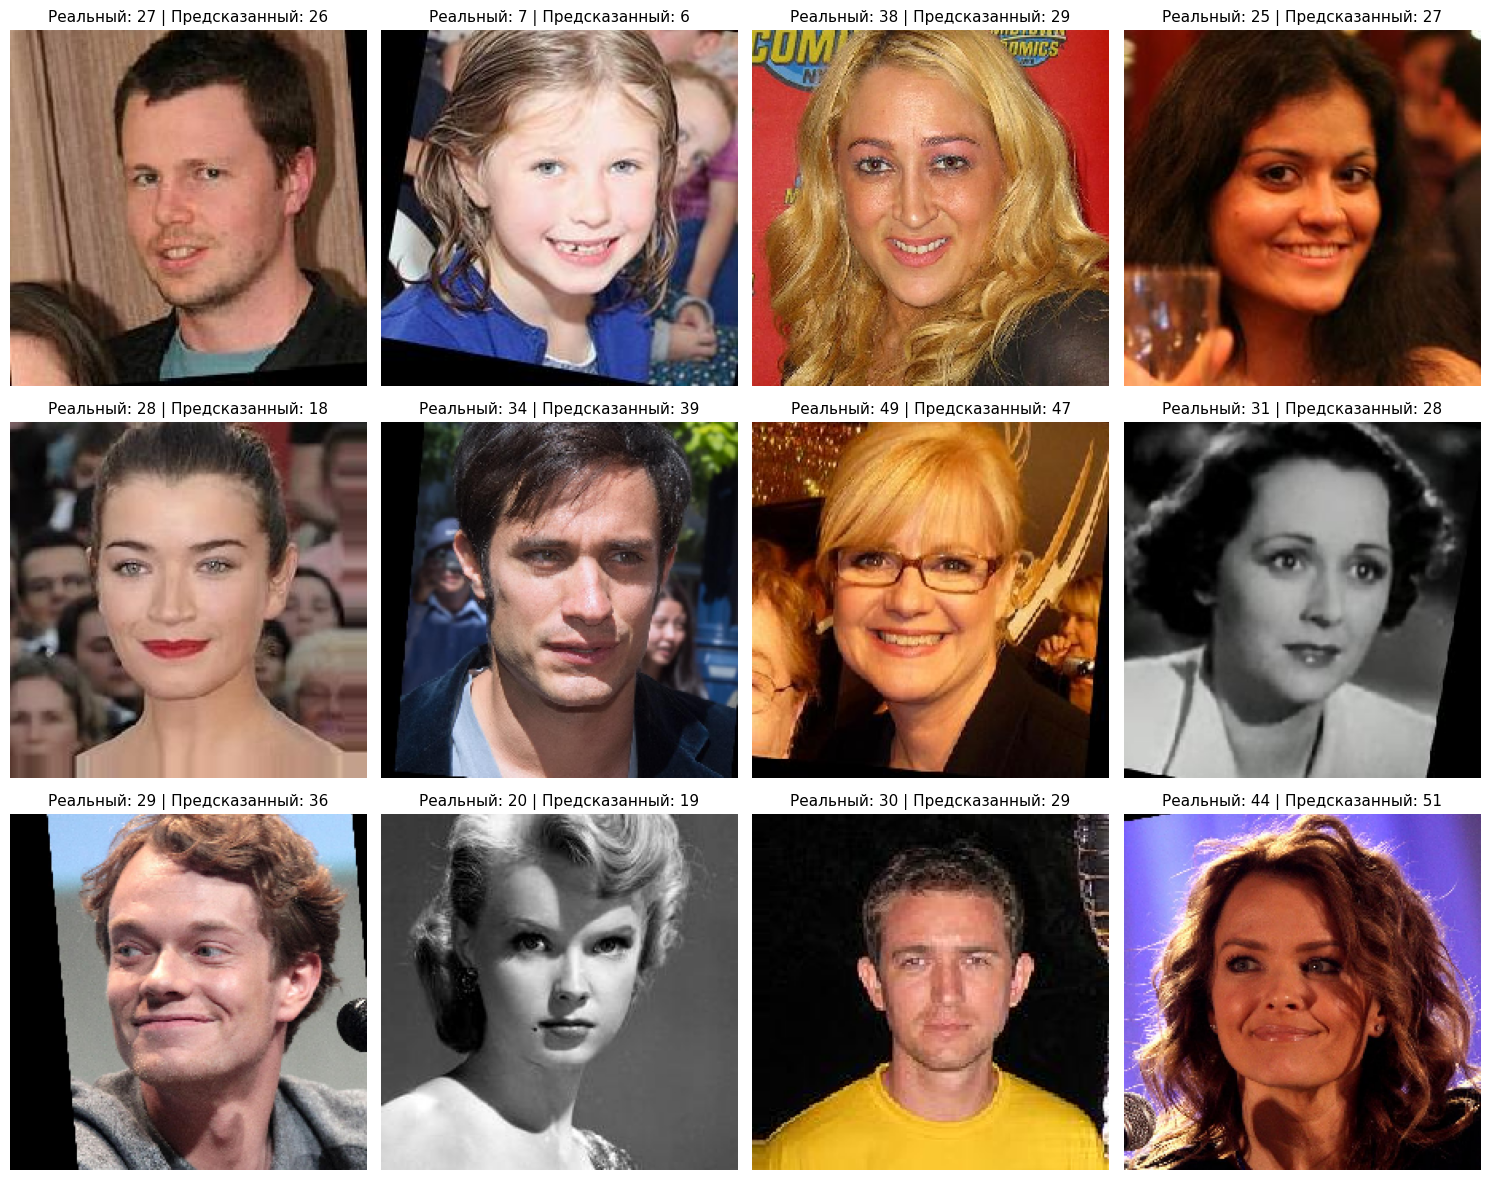

In [31]:
x_batch, y_batch = next(test_data)

preds = model.predict(x_batch, verbose=0)

fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(15, 12))

for i, ax in enumerate(axes.flatten()):
    img = x_batch[i]        # Готовая картинка
    real_age = y_batch[i]   # Реальный возраст
    pred_age = preds[i][0]  # Предсказанный возраст
    
    ax.imshow(img)
    ax.set_title(f"Реальный: {real_age:.0f} | Предсказанный: {pred_age:.0f}", fontsize=11)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Выводы

В ходе выполнения проекта была решена задача построения модели компьютерного зрения для сетевого супермаркета, способной определять приближенный возраст покупателя по фотографии.

**Основные этапы и результаты работы:**
1. **Предобработка данных:** Проведен первичный анализ данных, удалены лишние признаки (`apparent_age`, `worker_age`, `worker_gender`), устранены дубликаты, возникшие из-за особенностей разметки разными асессорами.
2. **Исследовательский анализ (EDA):** Анализ распределения возраста показал основную концентрацию покупателей в диапазоне от 20 до 40 лет, наличие пиков на «круглых» датах (эффект округления разметчиками) и всплеск в категории детей.
3. **Моделирование:**
* **Бэкбон:** `ResNet50` , предобученный на ImageNet.
* **Пулинг:** `GlobalAveragePooling2D()` для сжатия карт признаков в вектор.
* **Выходной слой:** `Dense(units=1, activation='linear')` для предсказания непрерывного значения возраста.
* **Компиляция:** Оптимизатор `Adam` (lr=0.0001), функция потерь `MSE`, метрика качества `MAE`.
4. **Итоговая метрика:** На тестовой выборке была достигнута средняя абсолютная ошибка **MAE = 7.30 лет**.

**Рекомендации для бизнеса:**
* **Анализ покупок и рекомендации:** Достигнутая точность (погрешность в среднем около 7 лет) является достаточной для решения маркетинговых задач — анализа клиентской базы и персонализированных рекомендаций товаров для ключевых возрастных групп.
* **Контроль продажи алкоголя:** Поскольку погрешность модели составляет около ±7 лет, ее **нельзя** использовать как единственный инструмент для автоматической проверки совершеннолетия. Ошибка вблизи порога 18 лет критична. Модель может применяться исключительно как вспомогательный триггер (например, выводить кассиру предупреждение о необходимости проверить паспорт, если алгоритм оценивает возраст покупателя ниже 25–30 лет).